# Hourly totals that follow storm motion: KTLX, 5 May 2022

**Question.** Notebooks 01-02 add up rain by holding each scan's rate until the next scan, about 6 minutes
later. Cells that move several km in that time leave stripes, and the totals correlate less well with MRMS
than MRMS radar-only does (which corrects for motion). Does advection-corrected accumulation help?

**Method** (`radarwow.estimation.advection_accumulate`): Anagnostou & Krajewski (1999, JTECH,
doi:10.1175/1520-0426(1999)016<0189:RTRREP>2.0.CO;2), as in the pysteps example `advection_correction`.
Between consecutive scans, estimate the motion with pysteps' Lucas-Kanade optical flow, then at 1-minute steps
blend the earlier scan moved forward and the later scan moved back. Optical flow needs a regular grid, so rates
go onto a 1 km Cartesian grid first.

Same chain as notebook 02, with the VPR correction on. Reference: MRMS MultiSensor QPE Pass 2.

In [1]:
# Colab: uncomment to install (downloads ~700 MB of radar data on first run)
!pip install -q cfgrib eccodes pysteps opencv-python-headless "git+https://github.com/manmeet3591/radarwow-core" "git+https://github.com/manmeet3591/radarwow-kdp" "git+https://github.com/manmeet3591/radarwow-attenuation" "git+https://github.com/manmeet3591/radarwow-estimation" "git+https://github.com/manmeet3591/radarwow-classification" "git+https://github.com/manmeet3591/radarwow-verify"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.classification import MeltingLayerTracker, melting_layer_from_volume
from radarwow.core import nexrad_aws_files, open_volume
from radarwow.estimation import (SyntheticRainRate, ZhangQi2010VPR, ZRRelation, accumulate, advection_accumulate,
                                 polar_to_cartesian, to_fixed_azimuths)
from radarwow.kdp import Vulpiani2012KDP
from radarwow.verify import fetch_mrms, hrrr_freezing_level, scores, to_mrms_grid

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITE, START, END = "KTLX", "2022-05-05 06:00", "2022-05-05 11:00"
HOURS = [7, 8, 9, 10]
NG = 600  # gates to 150 km
RES = 1.0  # km

## 1. Rain rates for every volume, on a 1 km grid

In [3]:
files = nexrad_aws_files(SITE, START, END, cache_dir=f"{CACHE}/nexrad")
tracker = MeltingLayerTracker()
fz_cache = {}
RATES = ["synthetic + VPR", "Z-R Marshall-Palmer + VPR"]
cart = {k: [] for k in RATES}
for t, f in files:
    dt = open_volume(f, band="S")
    lat0, lon0, alt = float(dt["latitude"].values), float(dt["longitude"].values), float(dt["altitude"].values)
    hr = pd.Timestamp(t).round("h")
    if hr not in fz_cache:
        fz_cache[hr] = (hrrr_freezing_level(hr, lat0, lon0, f"{CACHE}/hrrr", 150) - alt) / 1e3
    ml, _ = melting_layer_from_volume(dt)
    use, _ = tracker.update(t, ml)
    mlb = use.bottom_km if use else None
    vpr = ZhangQi2010VPR(freezing_level_km=fz_cache[hr])
    vdt = vpr(dt)
    low = vpr.fits[0].sweep
    ds = vdt[low].to_dataset().isel(range=slice(0, NG))
    att = Testud2000ZPHI()(Vulpiani2012KDP()(ds, band="S"), band="S")
    el = float(np.nanmedian(ds["elevation"].values))
    rates = {"synthetic + VPR": SyntheticRainRate(temperature_c=20, ml_bottom_km=mlb)(att.assign(DBZH=att["DBZH_VPR"]), band="S")["RATE"],
             "Z-R Marshall-Palmer + VPR": ZRRelation(preset="marshall_palmer", z_max_dbz=53, ml_bottom_km=mlb)(ds.assign(DBZH=ds["DBZH_VPR"]), band="S")["RATE_Z"]}
    for k, v in rates.items():
        c = polar_to_cartesian(to_fixed_azimuths(v), el, max_km=150, res_km=RES)
        inside = np.hypot(*np.meshgrid(c["x"].values, c["y"].values)) <= 150
        cart[k].append((t, c.where(~inside, c.fillna(0.0))))  # no echo inside the range = no rain
grid = cart["synthetic + VPR"][0][1]
xx, yy = np.meshgrid(grid["x"].values, grid["y"].values)
lat = lat0 + yy / 111.2
lon = lon0 + xx / (111.2 * np.cos(np.deg2rad(lat0)))
dist = np.hypot(xx, yy)
gaps = np.diff([pd.Timestamp(t) for t, _ in cart["synthetic + VPR"]]).astype("timedelta64[s]").astype(float) / 60
display(Markdown(f"{len(files)} volumes; scan interval median {np.median(gaps):.1f} min, max {gaps.max():.1f} min."))

44 volumes; scan interval median 6.7 min, max 7.1 min.

## 2. Hourly totals: holding each scan vs following the motion

Scoring note: here a gate with no echo counts as 0 mm/h, so every cell within 150 km is scored for both methods.
Notebooks 01-02 instead scored only cells with echo in at least 48 minutes of the hour (rate was NaN without
echo), which drops dry and rain-edge cells; their numbers are therefore not directly comparable with these.

In [4]:
results, maps = [], {}
RINGS = [(0, 150), (0, 50), (50, 100), (100, 150)]
for h in HOURS:
    a, b = pd.Timestamp(f"2022-05-05 {h:02d}:00"), pd.Timestamp(f"2022-05-05 {h + 1:02d}:00")
    ref = fetch_mrms("gauge_corrected", b, f"{CACHE}/mrms")
    ro = fetch_mrms("radar_only", b, f"{CACHE}/mrms")
    for k in RATES:
        for how, fn in [("hold", accumulate), ("advection", advection_accumulate)]:
            kw = {"return_motion": True} if how == "advection" else {}
            acc = fn(cart[k], a, b, **kw)
            val = np.where(acc["VALID_MINUTES"].values >= 48, acc["ACCUM"].values, np.nan)
            maps[(h, k, how)] = val
            if how == "advection" and k == RATES[0]:
                maps[(h, "motion")] = (acc["U"].values, acc["V"].values)
            ours, theirs, d = to_mrms_grid(val, lat, lon, ref, dist)
            for lo_, hi_ in RINGS:
                m = (d >= lo_) & (d < hi_)
                results.append(dict(hour=f"{h:02d}-{h + 1:02d}", method=f"{k}, {how}", ring=f"{lo_}-{hi_} km", **scores(ours[m], theirs[m])))
    ones = np.where(np.isfinite(maps[(h, RATES[0], "hold")]), 1.0, np.nan)
    _, ro_v, _ = to_mrms_grid(ones, lat, lon, ro, dist)
    _, gc_v, d = to_mrms_grid(ones, lat, lon, ref, dist)
    for lo_, hi_ in RINGS:
        m = (d >= lo_) & (d < hi_)
        results.append(dict(hour=f"{h:02d}-{h + 1:02d}", method="MRMS radar-only", ring=f"{lo_}-{hi_} km", **scores(ro_v[m], gc_v[m])))
    maps[(h, "mrms")], maps[(h, "mrms_ro")] = ref, ro
res = pd.DataFrame(results)
order = [f"{k}, {how}" for k in RATES for how in ("hold", "advection")] + ["MRMS radar-only"]
for ring in ["0-150 km", "100-150 km"]:
    tab = res[res.ring == ring].pivot_table(index="method", columns="hour", values=["bias_ratio", "corr", "rmse"]).round(2)
    display(Markdown(f"**{ring}** (bias = total / MRMS gauge-corrected total; RMSE in mm)\n\n" + tab.loc[order].to_markdown()))

Pysteps configuration file found at: /Users/manmeet.singh/aircast/radar-wow/.venv/lib/python3.11/site-packages/pysteps/pystepsrc



**0-150 km** (bias = total / MRMS gauge-corrected total; RMSE in mm)

| method                               |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |   ('rmse', '07-08') |   ('rmse', '08-09') |   ('rmse', '09-10') |   ('rmse', '10-11') |
|:-------------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| synthetic + VPR, hold                |                      1.08 |                      1.03 |                      1.13 |                      1.01 |                0.89 |                0.9  |                0.89 |                0.74 |                2.1  |                1.9  |                1.53 |                2.17 |
| synthetic + VPR, advection           |                      1.04 |                      1.05 |                      1.12 |                      0.99 |                0.93 |                0.94 |                0.95 |                0.88 |                1.57 |                1.49 |                1.05 |                1.39 |
| Z-R Marshall-Palmer + VPR, hold      |                      1.01 |                      0.95 |                      1.08 |                      0.97 |                0.88 |                0.86 |                0.88 |                0.84 |                2.04 |                2.17 |                1.51 |                1.59 |
| Z-R Marshall-Palmer + VPR, advection |                      0.98 |                      0.96 |                      1.07 |                      0.95 |                0.93 |                0.91 |                0.94 |                0.9  |                1.72 |                1.93 |                1.2  |                1.31 |
| MRMS radar-only                      |                      1.12 |                      1.2  |                      1.32 |                      1.25 |                0.99 |                0.98 |                0.97 |                0.97 |                0.96 |                1.1  |                1.19 |                1.05 |

**100-150 km** (bias = total / MRMS gauge-corrected total; RMSE in mm)

| method                               |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |   ('rmse', '07-08') |   ('rmse', '08-09') |   ('rmse', '09-10') |   ('rmse', '10-11') |
|:-------------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| synthetic + VPR, hold                |                      1.04 |                      1.05 |                      1.28 |                      1.02 |                0.86 |                0.81 |                0.78 |                0.73 |                2.63 |                1.88 |                1.28 |                1.73 |
| synthetic + VPR, advection           |                      1    |                      1.04 |                      1.24 |                      1    |                0.91 |                0.87 |                0.83 |                0.8  |                2.01 |                1.49 |                1.07 |                1.48 |
| Z-R Marshall-Palmer + VPR, hold      |                      0.95 |                      1    |                      1.31 |                      0.98 |                0.86 |                0.79 |                0.8  |                0.75 |                2.55 |                1.87 |                1.31 |                1.67 |
| Z-R Marshall-Palmer + VPR, advection |                      0.91 |                      1    |                      1.27 |                      0.96 |                0.9  |                0.84 |                0.86 |                0.8  |                2.24 |                1.68 |                1.04 |                1.46 |
| MRMS radar-only                      |                      1.09 |                      1.35 |                      1.61 |                      1.38 |                0.98 |                0.98 |                0.95 |                0.97 |                1.16 |                1.19 |                1.32 |                1.16 |

## 3. What it looks like

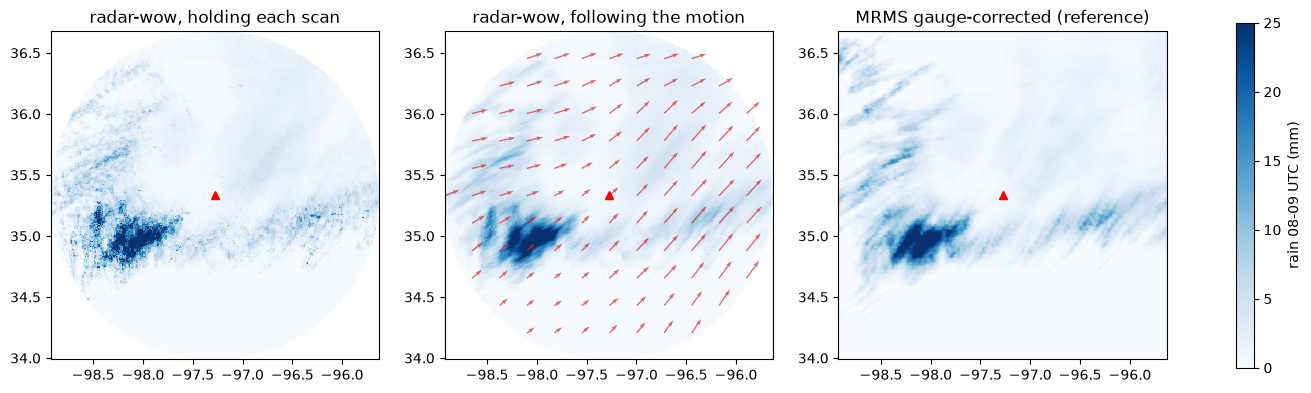

In [5]:
h = 8
ref = maps[(h, "mrms")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
kw = dict(cmap="Blues", vmin=0, vmax=25, shading="auto")
for ax, (title, v) in zip(axes[:2], [("holding each scan", maps[(h, RATES[0], "hold")]),
                                     ("following the motion", maps[(h, RATES[0], "advection")])]):
    m = ax.pcolormesh(lon, lat, np.ma.masked_invalid(v), **kw)
    ax.set_title(f"radar-wow, {title}")
box = ref.sel(latitude=slice(lat.max(), lat.min()), longitude=slice(lon.min(), lon.max()))
axes[2].pcolormesh(box.longitude, box.latitude, np.ma.masked_invalid(box.values), **kw)
axes[2].set_title("MRMS gauge-corrected (reference)")
u, v = maps[(h, "motion")]
sk = 25
in_ = dist[::sk, ::sk] <= 150
axes[1].quiver(lon[::sk, ::sk][in_], lat[::sk, ::sk][in_], u[::sk, ::sk][in_], v[::sk, ::sk][in_], color="C3", alpha=0.7, scale=1200, width=0.004)
for ax in axes:
    ax.set(xlim=(lon.min(), lon.max()), ylim=(lat.min(), lat.max()), aspect=1 / np.cos(np.deg2rad(lat0)))
    ax.plot(lon0, lat0, "r^")
fig.colorbar(m, ax=axes, label=f"rain {h:02d}-{h + 1:02d} UTC (mm)", shrink=0.8)
fig.savefig(f"{FIG}/08_advection_maps_{h:02d}.png", dpi=95, bbox_inches="tight")
plt.show()

In [6]:
spd = np.hypot(*maps[(h, "motion")])
display(Markdown(f"Median motion speed over the domain at {h:02d}-{h + 1:02d} UTC: {np.nanmedian(spd[dist <= 150]):.0f} km/h "
                 f"(red arrows; ~{np.nanmedian(spd[dist <= 150]) * np.median(gaps) / 60:.1f} km between scans)."))

Median motion speed over the domain at 08-09 UTC: 59 km/h (red arrows; ~6.6 km between scans).

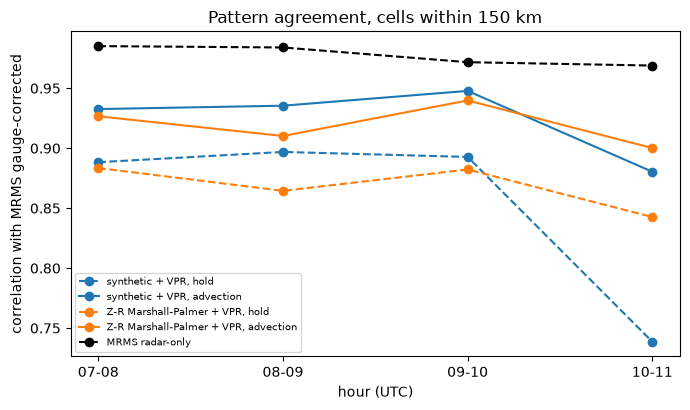

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.2))
r = res[res.ring == "0-150 km"]
for i, k in enumerate(order):
    g = r[r.method == k].sort_values("hour")
    ax.plot(g.hour, g["corr"], "o-" if "advection" in k else "o--", color="k" if "MRMS" in k else f"C{i // 2}", label=k)
ax.set(ylabel="correlation with MRMS gauge-corrected", xlabel="hour (UTC)", title="Pattern agreement, cells within 150 km")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG}/09_advection_corr.png", dpi=110)
plt.show()

## Takeaways
- **Following the motion fixes the streaks.** Storms moved at ~60 km/h, about 6.6 km between scans 6.7 minutes
  apart. Holding each scan paints a cell's footprint every 6.6 km; interpolating along the motion gives a smooth
  swath that looks like the MRMS reference.
- **Pattern agreement improves in every hour.** Correlation within 150 km for the synthetic estimate goes from
  0.89 / 0.90 / 0.89 / 0.74 to 0.93 / 0.94 / 0.95 / 0.88, and RMSE falls by 22-36 %. The weak last hour of
  notebook 01 (synthetic worse than plain Z-R) was mostly streaks: with motion it reaches 0.88.
- **Totals barely change**, as they should: moving rain around does not create or remove it (bias 1.01-1.13
  holding, 0.99-1.12 following).
- **Still behind MRMS radar-only in pattern** (0.97-0.99). It combines several radars, so each place is seen by
  the radar with the lowest beam over it; this is a single radar out to 150 km. Its totals overestimate more
  (1.12-1.32).
- **Scoring changed from notebooks 01-02.** Every cell within 150 km is scored here, with no echo counting as no
  rain; the earlier notebooks dropped cells with echo in fewer than 48 minutes of the hour.
- **Open:** motion from each pair of scans only (no smoothing in time); one case. The local build of pysteps on
  this Mac skips its compiled VET/Proesmans methods (macOS 27 SDK linker error); Lucas-Kanade does not need them.